# 🔬 Semi-Supervised Learning for Thermodynamic Stability (Alexandria)
## Demonstrating SSL with limited labeled data

---

### 🎯 Objective
Train with only **1,000 labeled compositions** and compare a supervised baseline with five semi-supervised methods (Label Propagation, Label Spreading, Self-Training, Co-Training, Cluster-then-Label) and self-supervised pre-training, while the unlabeled pool grows from 1,000 to 100,000 compositions.

The full sweep (3 seeds × 4 pool sizes × 2 unlabeled-pool settings, Optuna tuning) is run by `pipeline/run_ssl_experiments.py`; this notebook loads its results and re-runs every method once live.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
TASK = "stability"
PRED = ROOT / "data" / "predictions" / TASK
from IPython.display import Image, display

In [2]:
print("=" * 100); print("STEP 1: LOADING EXPERIMENT RESULTS"); print("=" * 100)
summ = {p: json.loads((PRED / p / f'ssl_summary_{TASK}.json').read_text()) for p in ('indist', 'gnome') if (PRED / p / f'ssl_summary_{TASK}.json').exists()}
res = {p: pd.read_csv(PRED / p / f'ssl_results_{TASK}.csv') for p in summ}
for p, s in summ.items():
    print(p, json.dumps(s['training_setup'], indent=1))

STEP 1: LOADING EXPERIMENT RESULTS
indist {
 "n_labeled_compositions_total": 436791,
 "n_train_pool": 349432,
 "n_test": 87359,
 "n_test_evaluated": 20000,
 "labeled_budget": 1000,
 "unlabeled_pool": "same database, labels hidden",
 "unlabeled_pool_size": 348432,
 "unlabeled_sizes_tested": [
  1000,
  5000,
  25000,
  100000
 ],
 "seeds": 3,
 "n_features": 142,
 "co_training_views": [
  132,
  10
 ],
 "stratified_sampling": true,
 "metric_used_for_selection": "Composite Score (mean of F1 & ROC-AUC), averaged over seeds"
}
gnome {
 "n_labeled_compositions_total": 436791,
 "n_train_pool": 349432,
 "n_test": 87359,
 "n_test_evaluated": 20000,
 "labeled_budget": 1000,
 "unlabeled_pool": "GNoME",
 "unlabeled_pool_size": 548412,
 "unlabeled_sizes_tested": [
  1000,
  5000,
  25000,
  100000
 ],
 "seeds": 3,
 "n_features": 142,
 "co_training_views": [
  132,
  10
 ],
 "stratified_sampling": true,
 "metric_used_for_selection": "Composite Score (mean of F1 & ROC-AUC), averaged over seeds"
}


In [3]:
print("STEP 2-3: BASELINE MODEL ZOO (supervised, 1,000 labels, mean over 3 seeds)")
r = res['indist']
zoo = r[r.Method == 'Baseline'].groupby('Config')[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Composite_Score']].agg(['mean', 'std'])
zoo.sort_values(('Composite_Score', 'mean'), ascending=False).round(4)

STEP 2-3: BASELINE MODEL ZOO (supervised, 1,000 labels, mean over 3 seeds)


Accuracy         Precision          Recall         F1-Score         ROC-AUC         Composite_Score        
                         mean     std      mean     std    mean     std     mean     std    mean     std            mean     std
Config                                                                                                                          
LightGBM (tuned)       0.7287  0.0021    0.5333  0.0032  0.6333  0.0057   0.5790  0.0031  0.7880  0.0025          0.6835  0.0025
LightGBM (default)     0.7479  0.0050    0.5874  0.0096  0.4844  0.0151   0.5309  0.0123  0.7805  0.0073          0.6557  0.0098
LogReg (default)       0.6879  0.0083    0.4788  0.0093  0.6638  0.0115   0.5562  0.0030  0.7458  0.0007          0.6510  0.0019
XGBoost (default)      0.7539  0.0051    0.6158  0.0105  0.4368  0.0174   0.5110  0.0148  0.7823  0.0080          0.6467  0.0113
XGBoost (tuned)        0.7548  0.0041    0.6326  0.0109  0.4000  0.0212   0.4899  0.0162  0.7837  0.0035          0.6368  0.0093
RF (default)           0.7480  0.0037    0.6468  0.0127  0.3187  0.0165   0.4268  0.0152  0.7720  0.0041          0.5994  0.0088
MLP (default)          0.7302  0.0056    0.5630  0.0216  0.3863  0.0398   0.4567  0.0211  0.7382  0.0067          0.5975  0.0083
ExtraTrees (default)   0.7436  0.0052    0.6204  0.0122  0.3329  0.0179   0.4333  0.0181  0.7582  0.0045          0.5957  0.0106
kNN (default)          0.7247  0.0022    0.5567  0.0072  0.3204  0.0014   0.4067  0.0020  0.7198  0.0049          0.5633  0.0035

In [4]:
print("STEP 4: OPTUNA HYPER-PARAMETER SEARCH (25 trials, 5-fold CV)")
pd.DataFrame({'CV composite': summ['indist']['optuna_cv_scores'], 'best params': {k: str(v) for k, v in summ['indist']['tuned_params'].items()}})

STEP 4: OPTUNA HYPER-PARAMETER SEARCH (25 trials, 5-fold CV)


,CV composite,best params
LightGBM,0.671841,"{'n_estimators': 300, 'num_leaves': 22, 'learn..."
XGBoost,0.621232,"{'n_estimators': 300, 'max_depth': 8, 'learnin..."


In [5]:
print("STEP 4b: SELF-SUPERVISED PRE-TRAINING (masked autoencoder on 554k GNoME)")
r[r.Method == 'Self-Supervised (AE)'].groupby('Config')[['F1-Score', 'ROC-AUC', 'Composite_Score']].agg(['mean', 'std']).round(4)

STEP 4b: SELF-SUPERVISED PRE-TRAINING (masked autoencoder on 554k GNoME)


F1-Score         ROC-AUC         Composite_Score        
                                 mean     std    mean     std            mean     std
Config                                                                               
LightGBM* on ae features       0.5185  0.0097  0.7290  0.0067          0.6237  0.0080
LightGBM* on raw+ae features   0.5661  0.0071  0.7798  0.0020          0.6729  0.0045

In [6]:
print("STEP 5-8: SEMI-SUPERVISED SWEEP – mean composite per pool size")
for p, r_ in res.items():
    print(f'--- unlabeled pool: {p}')
    ssl = r_[~r_.Method.isin(['Baseline', 'Self-Supervised (AE)'])]
    display(ssl.pivot_table(index=['Method', 'Config'], columns='N_Unlabeled', values='Composite_Score', aggfunc='mean').round(4))

STEP 5-8: SEMI-SUPERVISED SWEEP – mean composite per pool size
--- unlabeled pool: indist


N_Unlabeled                                                 1000    5000    25000   100000
Method             Config                                                                 
Cluster-then-Label CtL LightGBM* k=100 purity=0.8           0.6839  0.6636  0.6508  0.6409
                   CtL LightGBM* k=100 purity=0.8 [raw+AE]  0.6744  0.6656  0.6407  0.6210
Co-Training        CT LightGBM* tau=0.85                    0.6885  0.6498  0.6119  0.5878
                   CT RF tau=0.85                           0.5900  0.5876     NaN     NaN
Label Propagation  LP knn k=10                              0.5945  0.5843  0.5624  0.5297
                   LP rbf                                   0.5809  0.5798     NaN     NaN
Label Spreading    LS knn k=10 alpha=0.2                    0.5959  0.5782  0.5574  0.5392
                   LS knn k=10 alpha=0.2 [AE space]         0.5923  0.5680  0.5552  0.5384
                   LS knn k=10 alpha=0.8                    0.5979  0.5890  0.5676  0.5466
                   LS rbf alpha=0.2                         0.5777  0.5680     NaN     NaN
Self-Training      ST LightGBM* tau=0.75                    0.6787  0.6615     NaN     NaN
                   ST LightGBM* tau=0.9                     0.6836  0.6784  0.6534  0.6480
                   ST LightGBM* tau=0.9 [raw+AE]            0.6754  0.6724     NaN     NaN
                   ST RF tau=0.75                           0.5631  0.4858     NaN     NaN

--- unlabeled pool: gnome


N_Unlabeled                                                 1000    5000    25000   100000
Method             Config                                                                 
Cluster-then-Label CtL LightGBM* k=100 purity=0.8           0.6683  0.6494  0.6161  0.5817
                   CtL LightGBM* k=100 purity=0.8 [raw+AE]  0.6577  0.6391  0.6064  0.5736
Co-Training        CT LightGBM* tau=0.85                    0.6840  0.5953  0.5534  0.5249
                   CT RF tau=0.85                           0.5666  0.5324     NaN     NaN
Label Propagation  LP knn k=10                              0.5569  0.5198  0.4790  0.4669
                   LP rbf                                   0.5878  0.5852     NaN     NaN
Label Spreading    LS knn k=10 alpha=0.2                    0.5540  0.5245  0.5029  0.5250
                   LS knn k=10 alpha=0.2 [AE space]         0.5546  0.5310  0.5185  0.5301
                   LS knn k=10 alpha=0.8                    0.5555  0.5323  0.5068  0.4989
                   LS rbf alpha=0.2                         0.5859  0.5706     NaN     NaN
Self-Training      ST LightGBM* tau=0.75                    0.6483  0.6142     NaN     NaN
                   ST LightGBM* tau=0.9                     0.6821  0.6801  0.6689  0.6154
                   ST LightGBM* tau=0.9 [raw+AE]            0.6736  0.6716     NaN     NaN
                   ST RF tau=0.75                           0.5078  0.4373     NaN     NaN

In [7]:
print("STEP 9: COMPREHENSIVE RESULTS COMPARISON (best configuration per method)")
for p, s in summ.items():
    print(f'--- unlabeled pool: {p}')
    b = pd.DataFrame(s['best_per_method'])[['Method', 'Model_Config', 'Composite_Score_mean', 'Composite_Score_std', 'F1-Score_mean', 'ROC-AUC_mean', 'Accuracy_mean']]
    display(b.round(4))
    print('SSL vs best baseline: %+.2f %%' % s['ssl_improvement_over_best_baseline_pct'])

STEP 9: COMPREHENSIVE RESULTS COMPARISON (best configuration per method)
--- unlabeled pool: indist


,Method,Model_Config,Composite_Score_mean,Composite_Score_std,F1-Score_mean,ROC-AUC_mean,Accuracy_mean
0,Co-Training,CT LightGBM* tau=0.85 | n=1000,0.6885,0.0062,0.5827,0.7944,0.7300
1,Cluster-then-Label,CtL LightGBM* k=100 purity=0.8 | n=1000,0.6839,0.0031,0.5820,0.7859,0.7205
2,Self-Training,ST LightGBM* tau=0.9 | n=1000,0.6836,0.0028,0.5820,0.7853,0.7201
3,Baseline,LightGBM (tuned),0.6835,0.0025,0.5790,0.7880,0.7287
4,Self-Supervised (AE),LightGBM* on raw+ae features,0.6729,0.0045,0.5661,0.7798,0.7255
5,Label Spreading,LS knn k=10 alpha=0.8 | n=1000,0.5979,0.0047,0.4859,0.7100,0.7006
6,Label Propagation,LP knn k=10 | n=1000,0.5945,0.0062,0.4809,0.7081,0.6980


SSL vs best baseline: +0.73 %
--- unlabeled pool: gnome


,Method,Model_Config,Composite_Score_mean,Composite_Score_std,F1-Score_mean,ROC-AUC_mean,Accuracy_mean
0,Co-Training,CT LightGBM* tau=0.85 | n=1000,0.6840,0.0102,0.5810,0.7869,0.7304
1,Baseline,LightGBM (tuned),0.6835,0.0025,0.5790,0.7880,0.7287
2,Self-Training,ST LightGBM* tau=0.9 | n=1000,0.6821,0.0015,0.5773,0.7869,0.7264
3,Self-Supervised (AE),LightGBM* on raw+ae features,0.6729,0.0045,0.5661,0.7798,0.7255
4,Cluster-then-Label,CtL LightGBM* k=100 purity=0.8 | n=1000,0.6683,0.0047,0.5647,0.7718,0.7170
5,Label Propagation,LP rbf | n=1000,0.5878,0.0188,0.4786,0.6969,0.6785
6,Label Spreading,LS rbf alpha=0.2 | n=1000,0.5859,0.0200,0.4779,0.6938,0.6756


SSL vs best baseline: +0.06 %


STEP 10: LEARNING CURVES


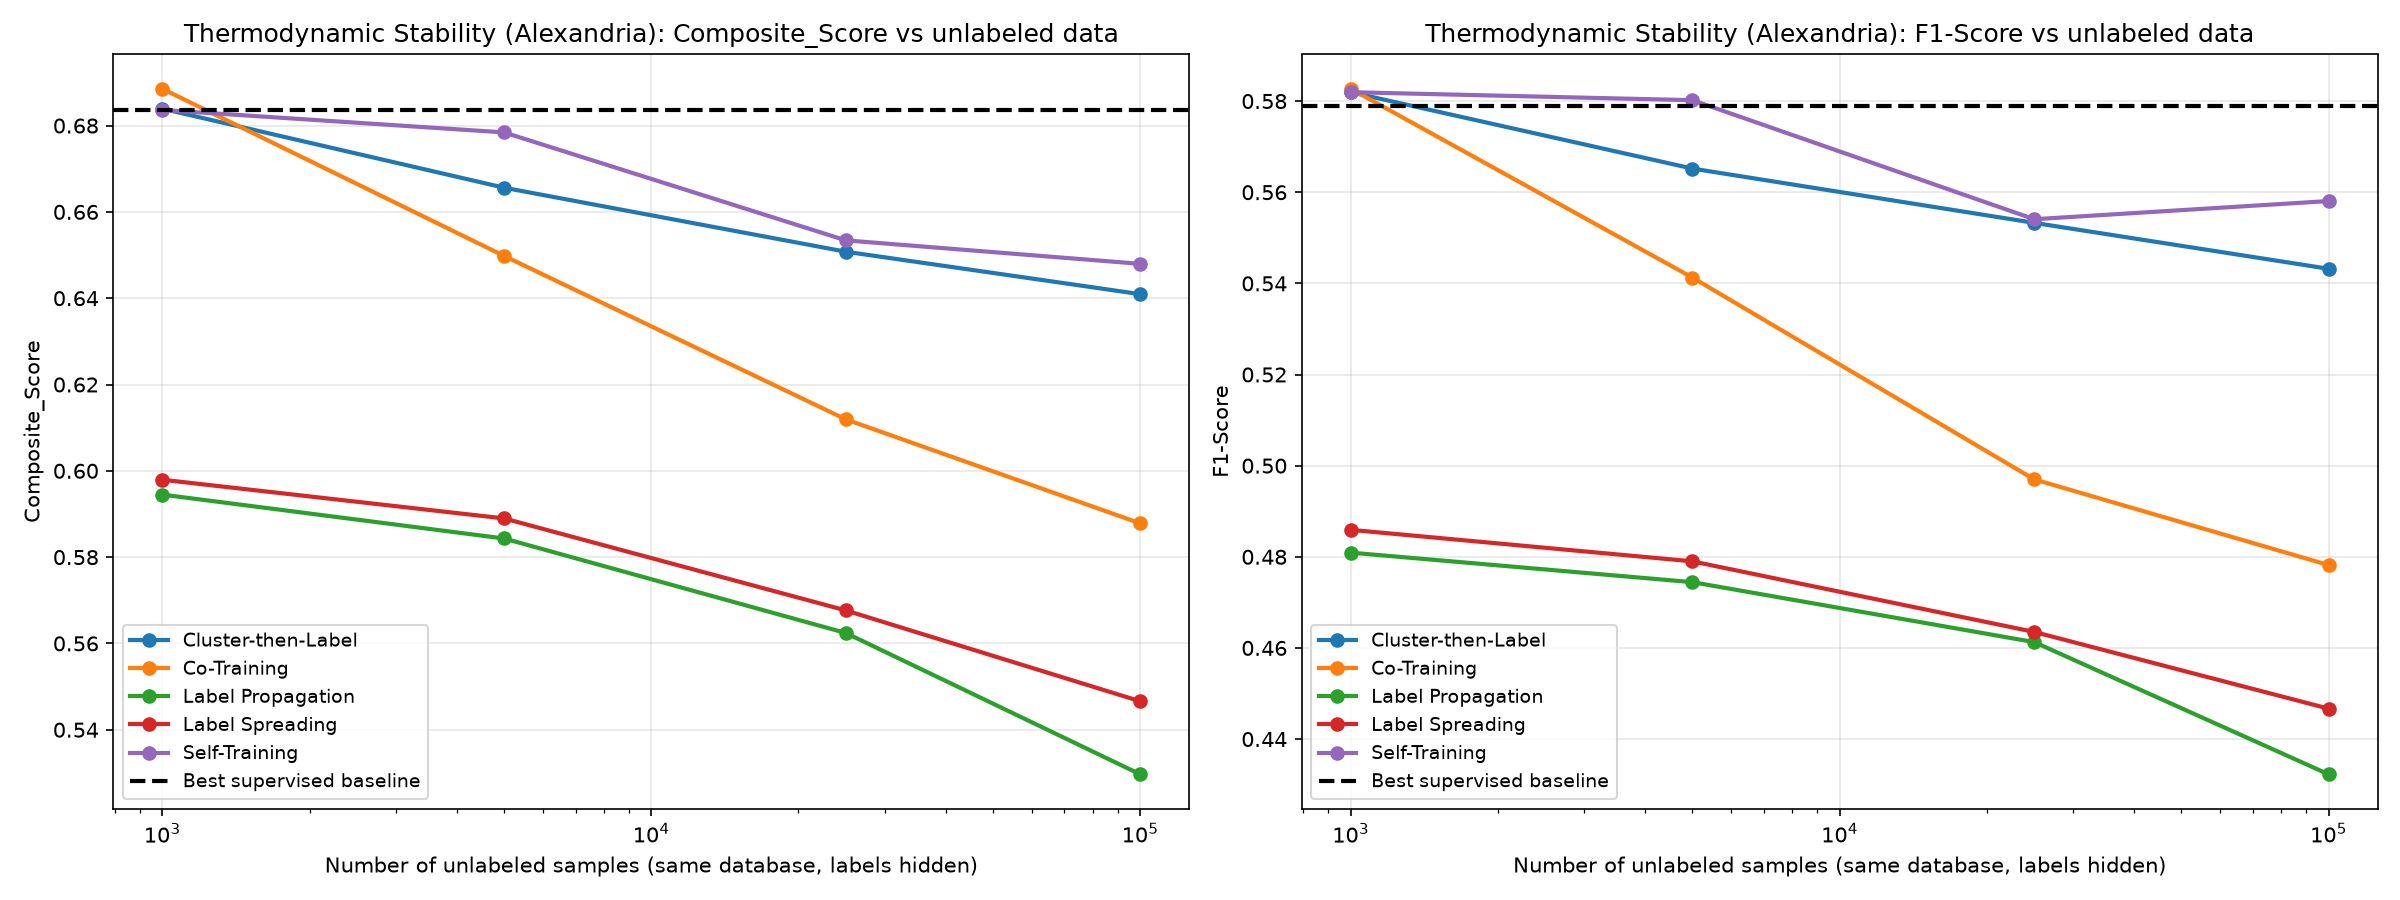

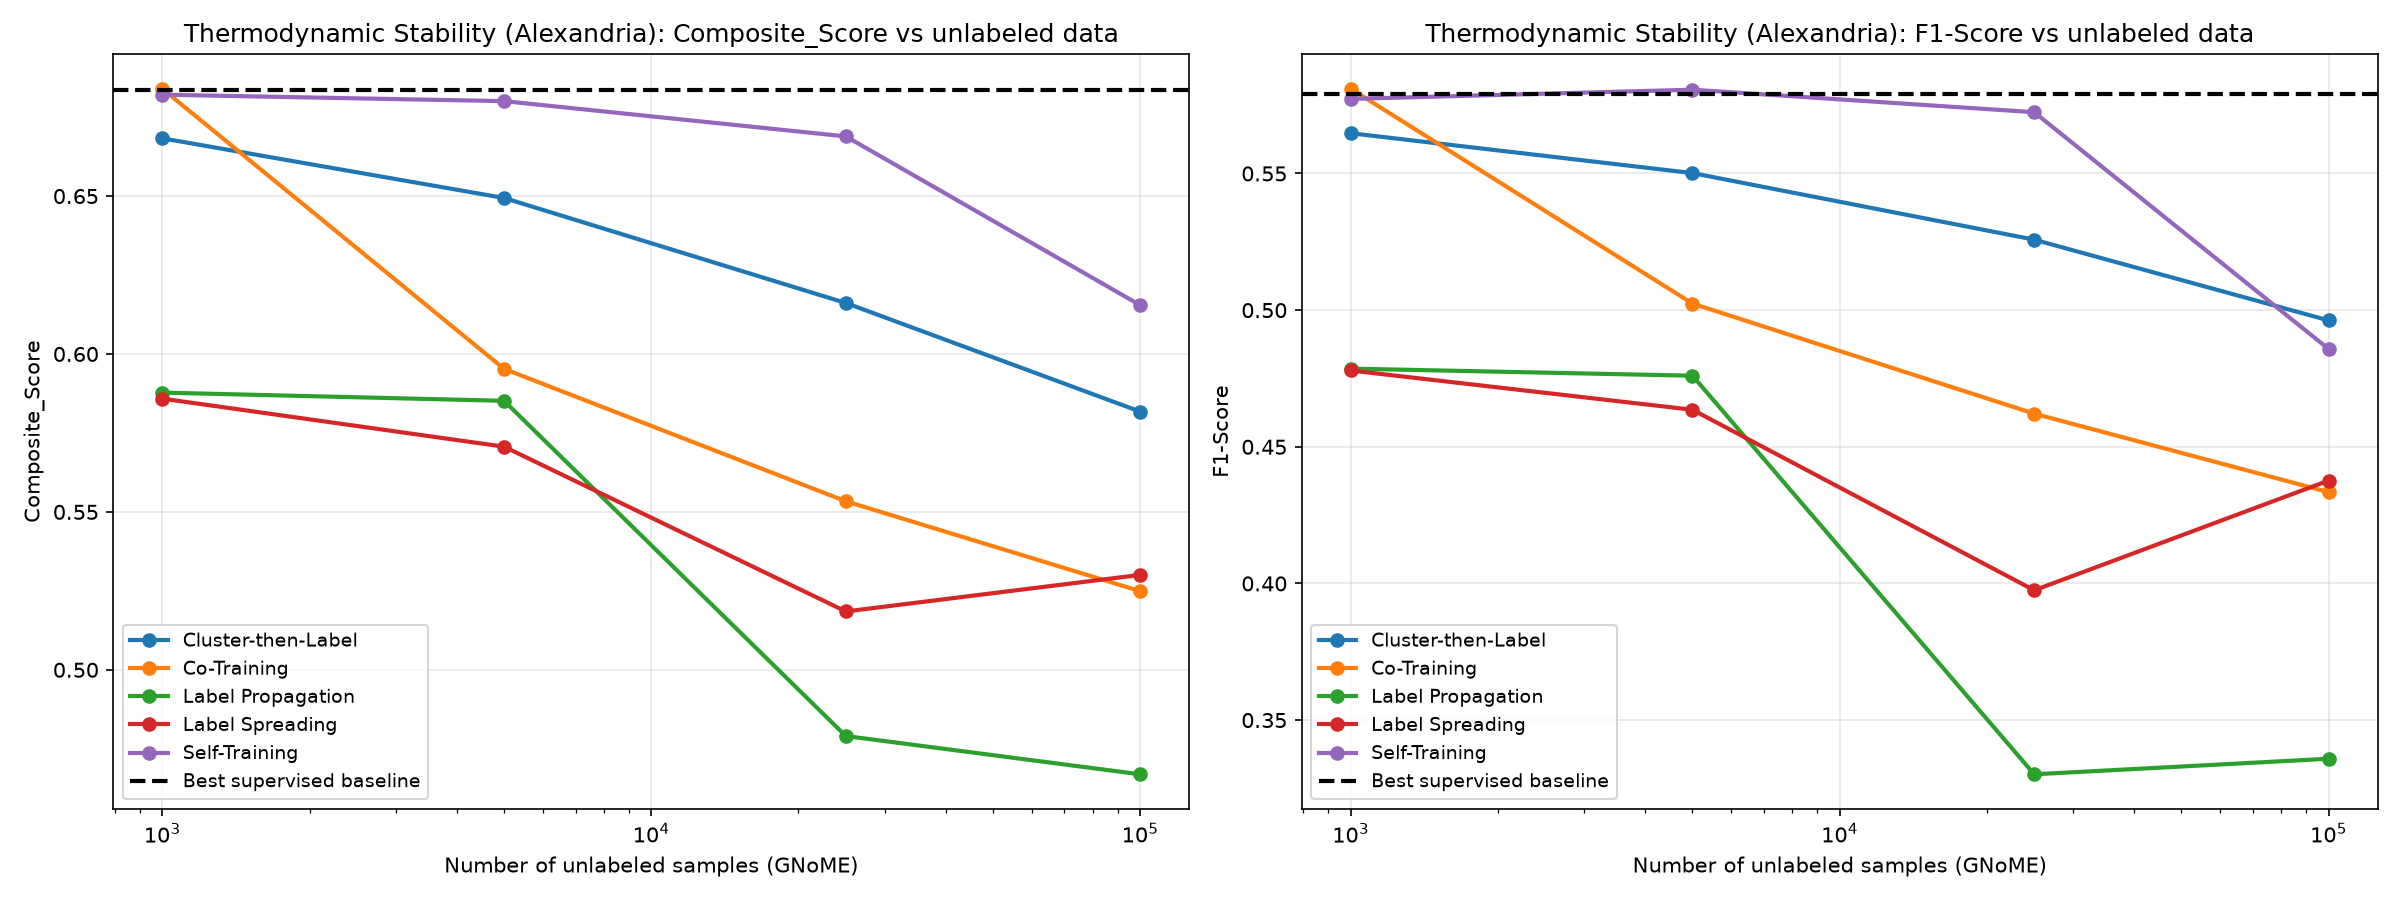

In [8]:
print("STEP 10: LEARNING CURVES")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_learning_curves.png')))

STEP 11: BEST MODELS COMPARISON (balanced composite metric)


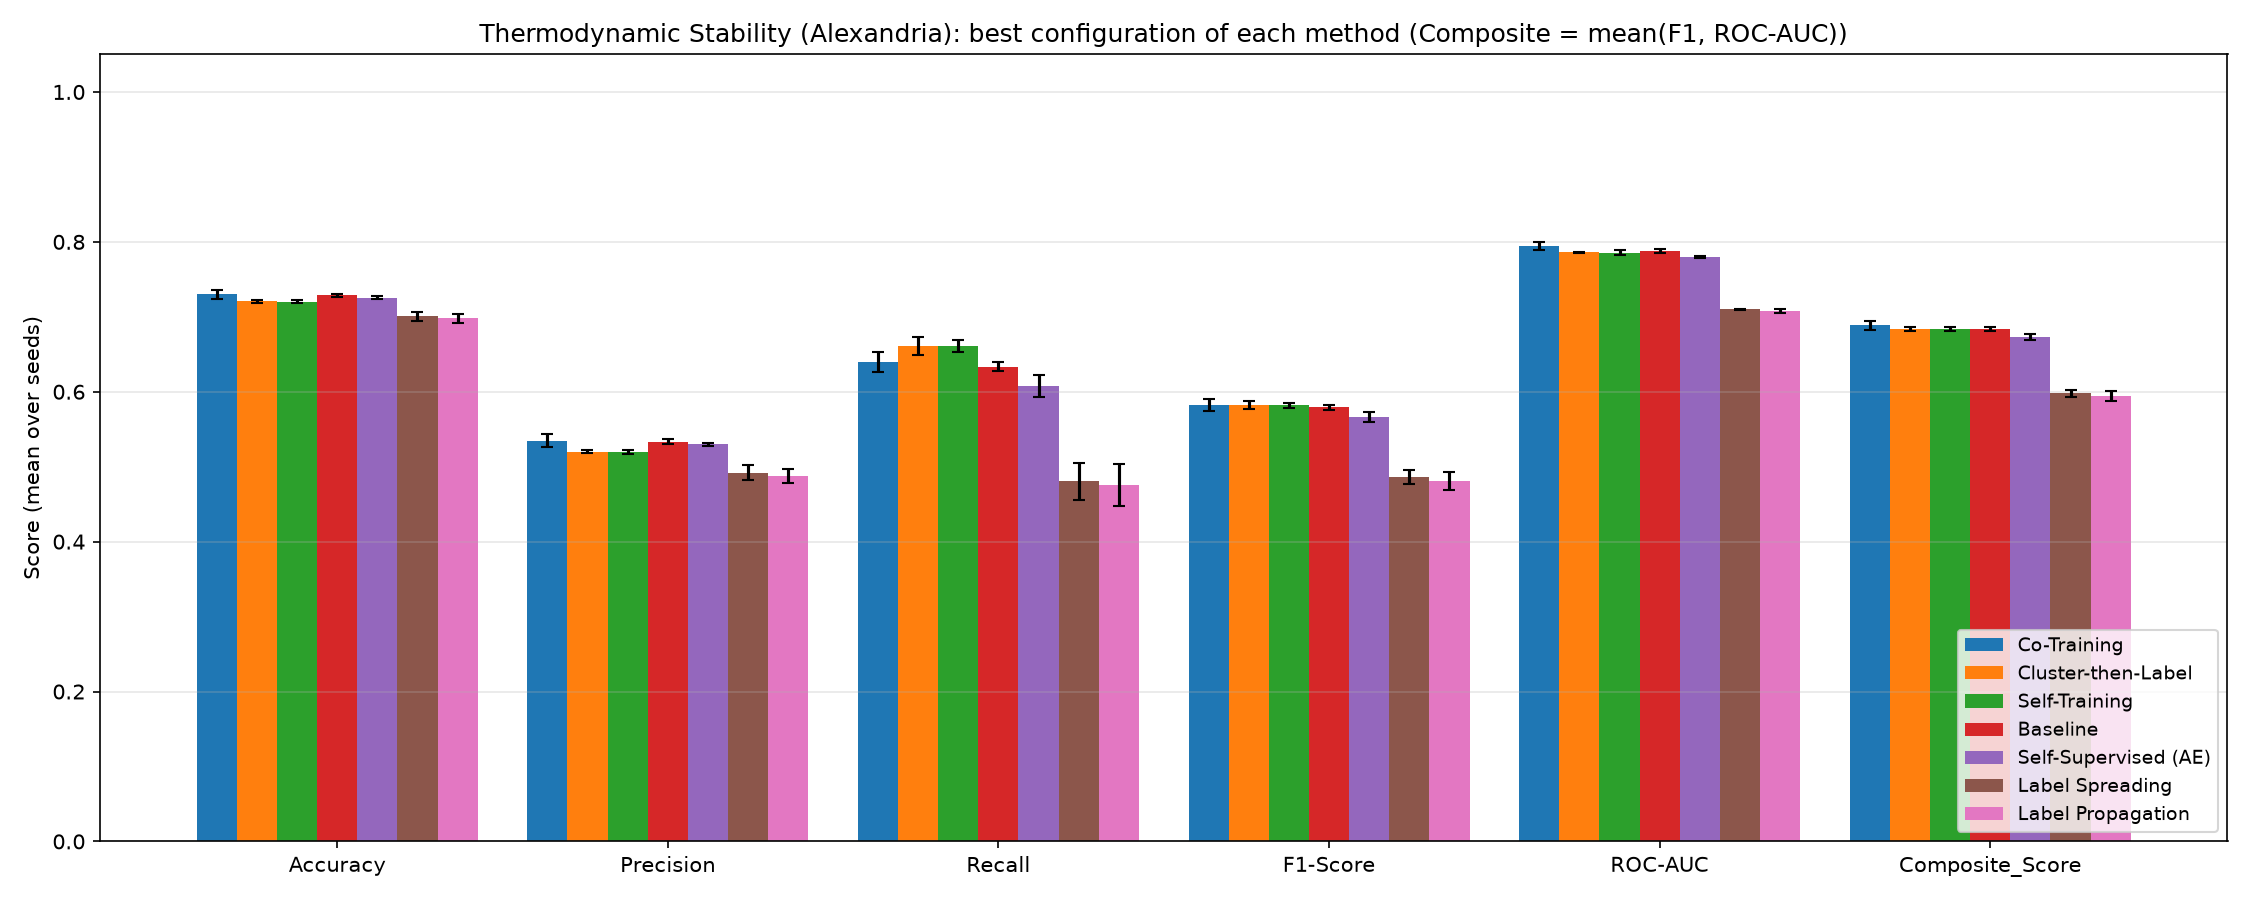

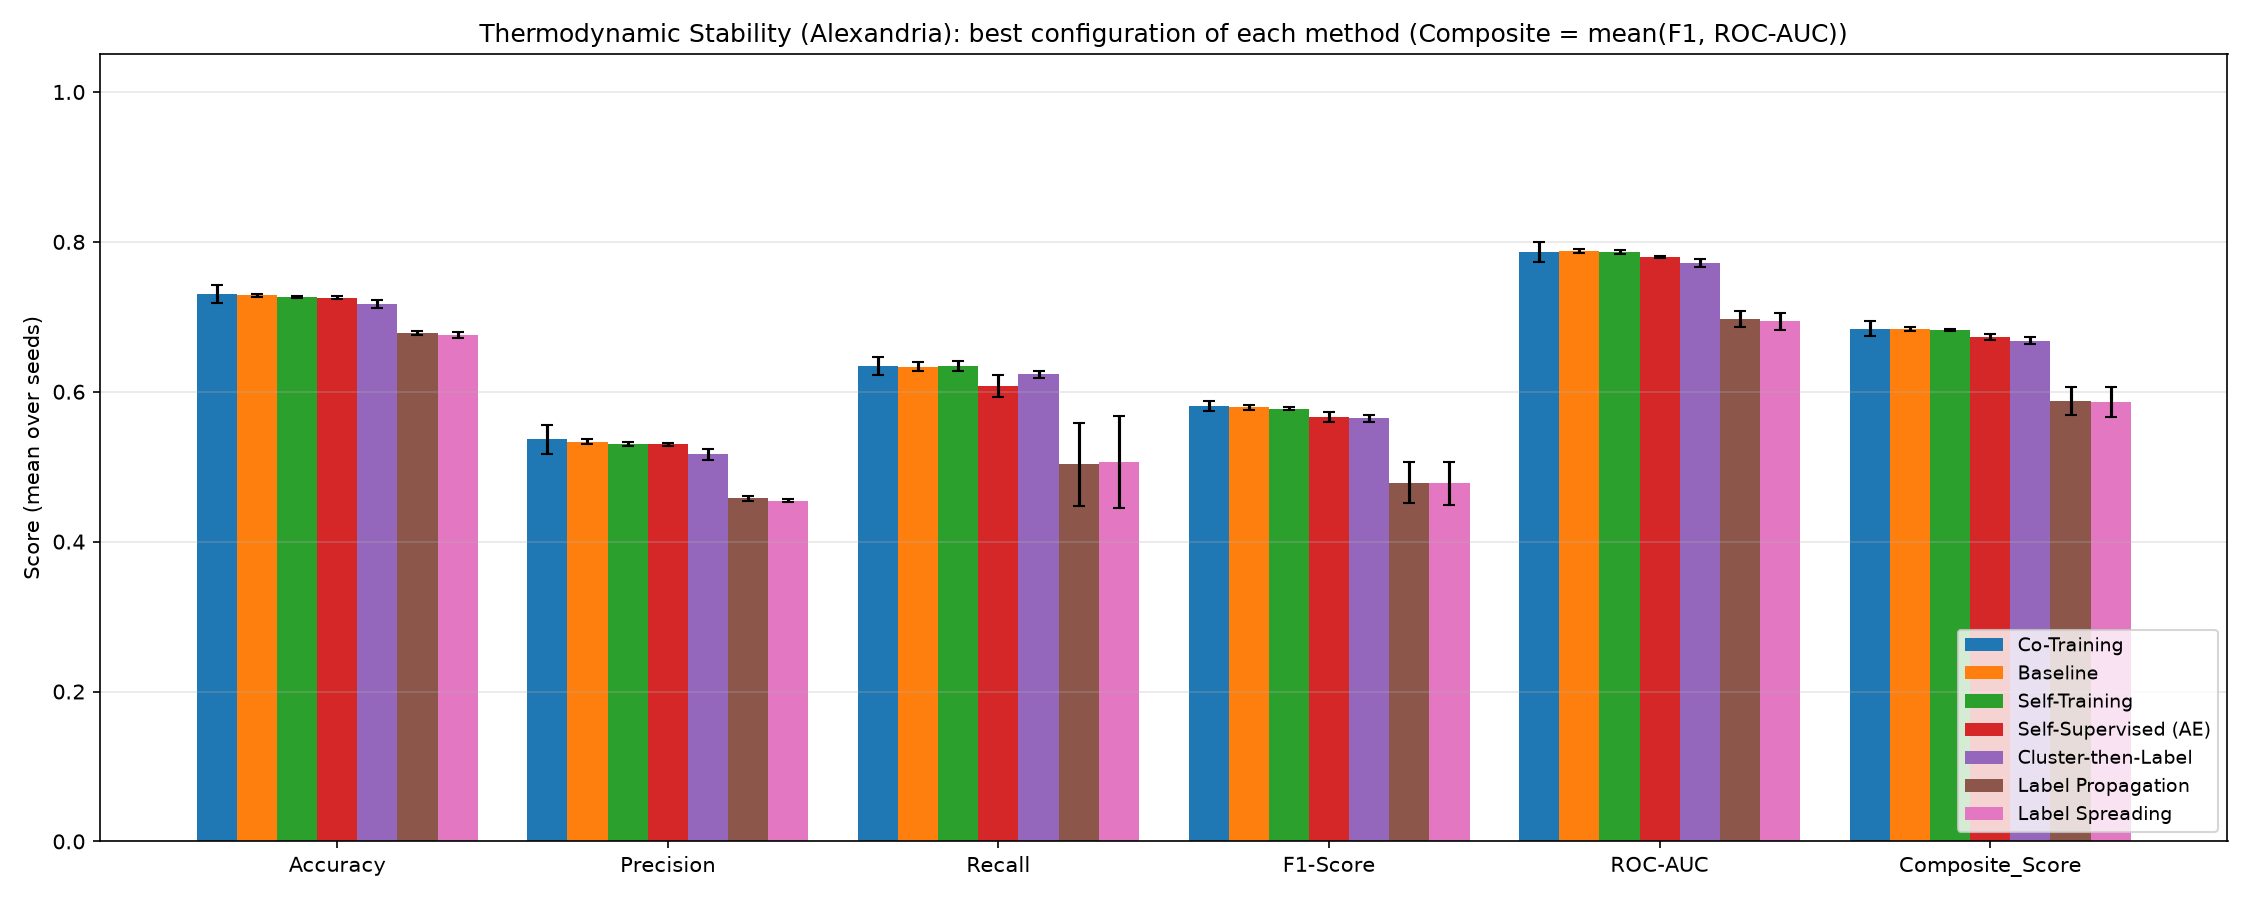

In [9]:
print("STEP 11: BEST MODELS COMPARISON (balanced composite metric)")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_methods_comparison_balanced.png')))

STEP 12: LABEL-BUDGET CURVE AND FULLY-SUPERVISED UPPER BOUND


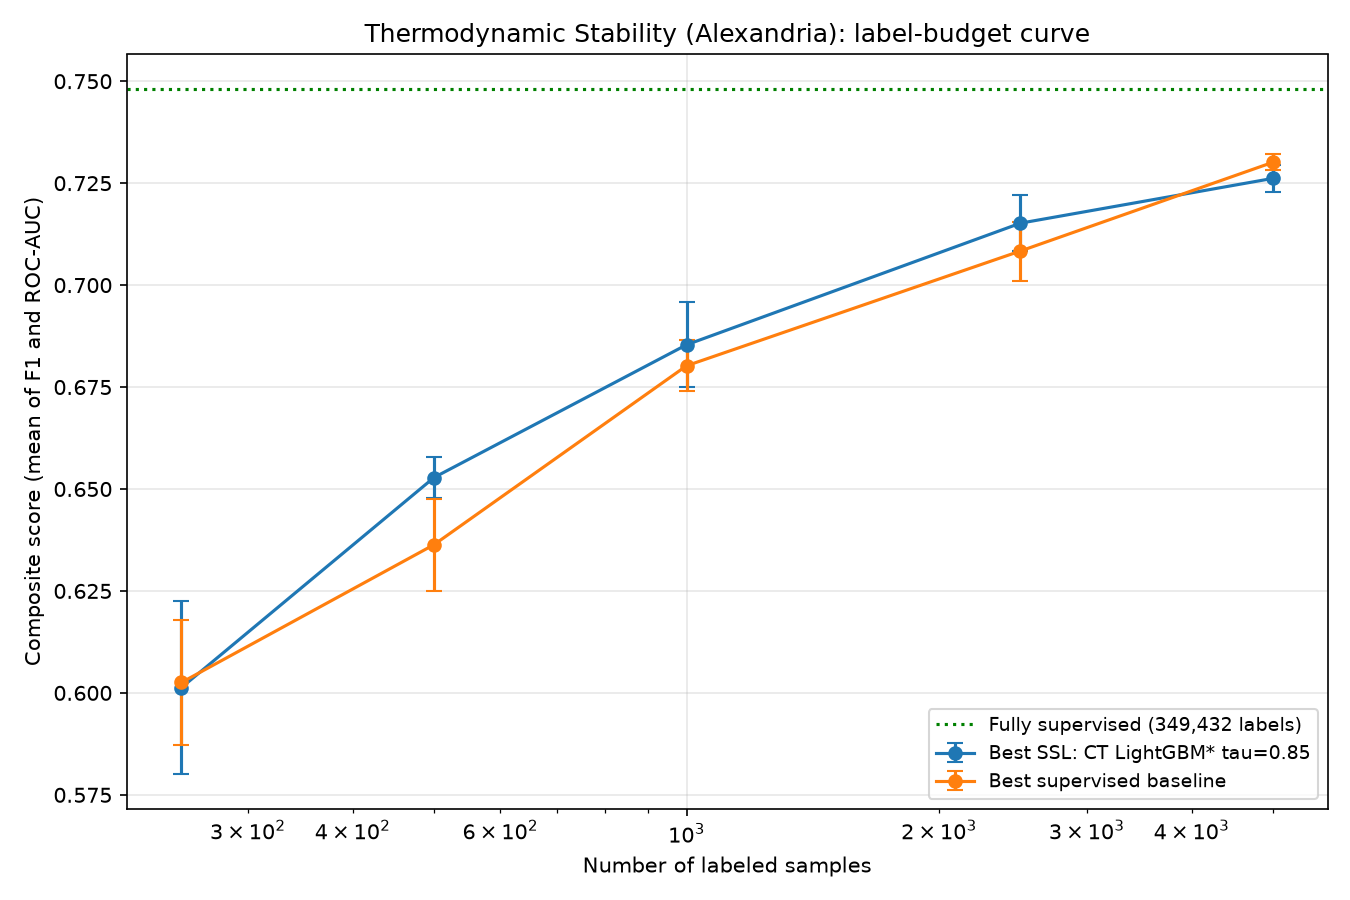

indist fully supervised: {'Composite_Score': 0.7481429810593225, 'F1-Score': 0.6478055367994598, 'ROC-AUC': 0.8484804253191851, 'Accuracy': 0.7392}


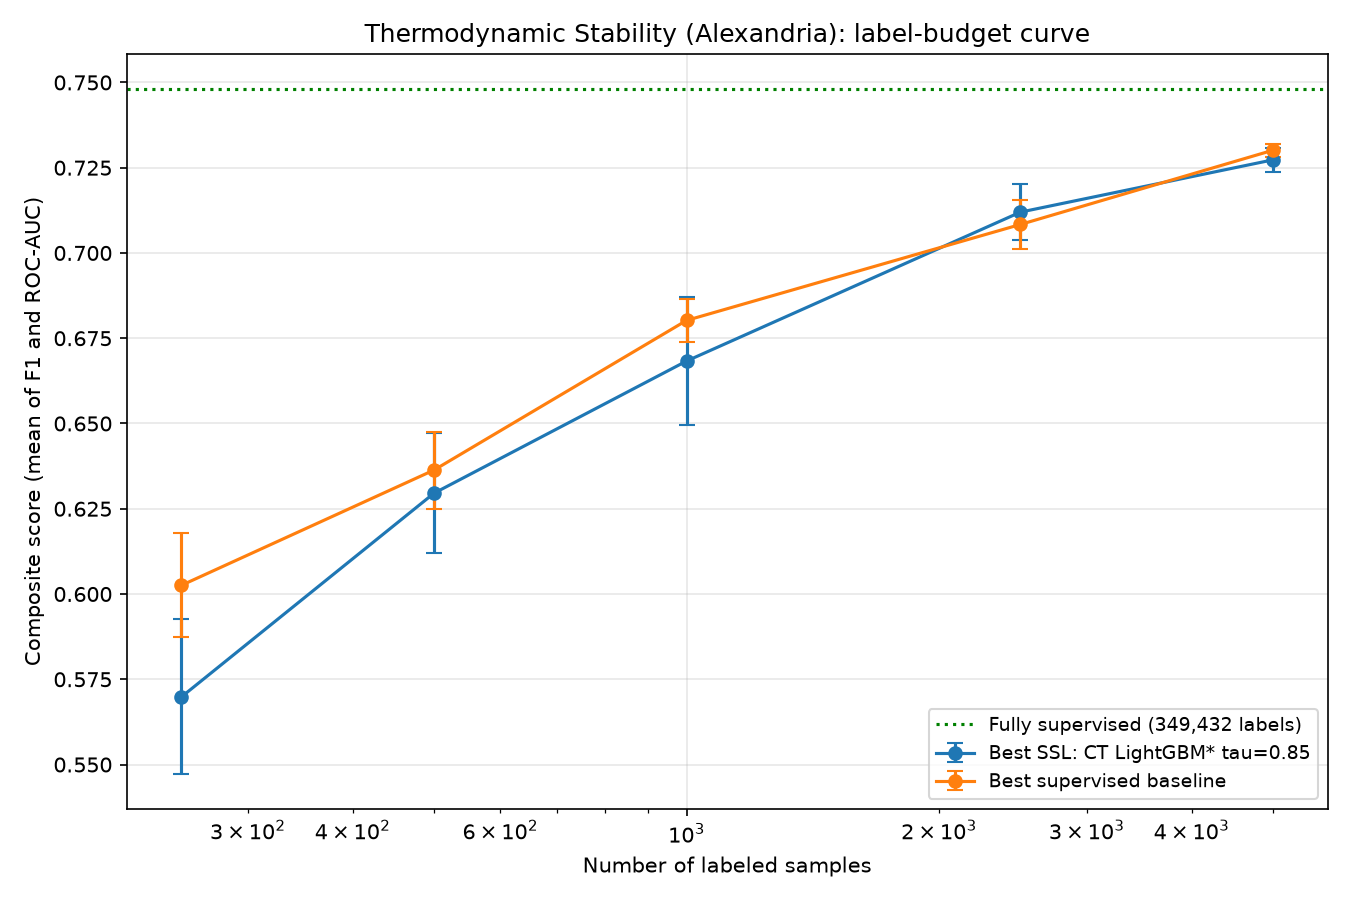

gnome fully supervised: {'Composite_Score': 0.7481429810593225, 'F1-Score': 0.6478055367994598, 'ROC-AUC': 0.8484804253191851, 'Accuracy': 0.7392}


In [10]:
print("STEP 12: LABEL-BUDGET CURVE AND FULLY-SUPERVISED UPPER BOUND")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_label_budget_curve.png')))
    print(p, 'fully supervised:', summ[p]['fully_supervised_upper_bound'])

### Live run: every method once (seed 0, 1,000 labels, 5,000 unlabeled)

In [11]:
import ssl_core as core
from run_ssl_experiments import Preprocessor, stratified_take
from featurize import view_columns
from sklearn.model_selection import train_test_split
lab = pd.read_parquet(ROOT / 'data/processed' / f'{TASK}_features.parquet')
feat = [c for c in lab.columns if c.startswith(('MagpieData', 'frac ')) or c.endswith('-norm')]
tr, te = train_test_split(np.arange(len(lab)), test_size=0.2, stratify=lab.target, random_state=42)
prep = Preprocessor().fit(lab.iloc[tr][feat])
Xtr, ytr = prep.transform(lab.iloc[tr][feat]), lab.target.values[tr]
Xte, yte = prep.transform(lab.iloc[te][feat]), lab.target.values[te]
rng = np.random.default_rng(0)
li = stratified_take(ytr, 1000, rng)
rest = rng.permutation(np.setdiff1d(np.arange(len(ytr)), li))[:5000]
keep = stratified_take(yte, min(10000, len(yte)), rng)
d = core.Data(Xtr[li], ytr[li], Xtr[rest], Xte[keep], yte[keep])
v1n, v2n = view_columns()
v2 = [i for i, c in enumerate(prep.cols) if c in v2n or (any(k in c for k in ('Valence', 'Unfilled', 'Column', 'Row')) and (c.endswith(' mean') or c.endswith(' avg_dev')))]
v1 = [i for i in range(len(prep.cols)) if i not in v2]
best = summ['indist']['best_supervised_baseline']['config'].split(' ')[0]
params = summ['indist']['tuned_params'].get(best, {})
runs = [core.run_baseline(d, best, params=params)[0],
        core.run_label_propagation(d, 'knn', n_neighbors=10)[0],
        core.run_label_propagation(d, 'knn', n_neighbors=10, spreading=True)[0],
        core.run_self_training(d, best, threshold=0.9, max_iter=5, params=params)[0],
        core.run_co_training(d, v1, v2, best, threshold=0.85, n_rounds=8, params=params)[0],
        core.run_cluster_then_label(d, best, params=params)[0]]
pd.DataFrame(runs)[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Composite_Score', 'Training_Time']].round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Composite_Score,Training_Time
0,Baseline LightGBM (1000 labeled),0.7310,0.5376,0.6190,0.5754,0.7834,0.6794,0.6344
1,"LabelPropagation (knn, k=10, n=5000)",0.6929,0.4792,0.4917,0.4853,0.6941,0.5897,0.9670
2,"LabelSpreading (knn, k=10, alpha=0.2, n=5000)",0.6888,0.4723,0.4839,0.4780,0.6894,0.5837,1.1005
3,"SelfTraining-LightGBM (tau=0.9, n=5000)",0.7021,0.4958,0.6771,0.5724,0.7631,0.6677,3.9926
4,"CoTraining-LightGBM (tau=0.85, n=5000)",0.7115,0.5088,0.5902,0.5465,0.7602,0.6533,9.4975
5,"ClusterThenLabel-LightGBM (k=100, purity=0.8, ...",0.6852,0.4765,0.6988,0.5666,0.7624,0.6645,2.6825


In [12]:
print("STEP 13: DEPLOYED MODEL (selected architecture re-trained on all training labels)")
for p, s in summ.items():
    print(p, s['best_ssl_model']['Model_Config'], '->', s['deployment_model_test_metrics'])

STEP 13: DEPLOYED MODEL (selected architecture re-trained on all training labels)
indist CT LightGBM* tau=0.85 | n=1000 -> {'Composite_Score': 0.7438603142202804, 'F1-Score': 0.644770718808712, 'ROC-AUC': 0.8429499096318489, 'Accuracy': 0.74475, 'Precision': 0.5463443396226415, 'Recall': 0.78645391274826}
gnome CT LightGBM* tau=0.85 | n=1000 -> {'Composite_Score': 0.7438603142202804, 'F1-Score': 0.644770718808712, 'ROC-AUC': 0.8429499096318489, 'Accuracy': 0.74475, 'Precision': 0.5463443396226415, 'Recall': 0.78645391274826}
